In [29]:
# import necessities
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

data = pd.read_csv("../data/processed/train_features.csv")    # my 30 features (+ row_id, user_id, buy)

# hold out 20% of the users (same split as 03a): the model never sees them until the final check
dev_idx, hold_idx = next(StratifiedGroupKFold(5, shuffle=True, random_state=42).split(data, data["buy"], data["user_id"]))
train   = data.iloc[dev_idx].reset_index(drop=True)
holdout = data.iloc[hold_idx].reset_index(drop=True)

print(train.shape, holdout.shape)
print(train["user_id"].nunique(), "train users,", holdout["user_id"].nunique(), "holdout users")


(24000, 33) (6000, 33)
4800 train users, 1200 holdout users


ok, now drop anything that’s the answer, a name tag, a copy or constant.

In [30]:
# columns the model must not see: the answer and the two ids
drop_cols = ["buy", "row_id", "user_id"]

y_train   = train["buy"]
y_holdout = holdout["buy"]

X_train   = train.drop(columns=drop_cols)
X_holdout = holdout.drop(columns=drop_cols)

print(X_train.shape, X_holdout.shape)
print(X_train.columns.tolist())

(24000, 30) (6000, 30)
['age', 'education', 'spending_capacity_band', 'home_city', 'stated_favourite_genre', 'past_purchase_count', 'first_timer', 'typical_ticket_spend', 'usual_booking_lead_days', 'artist_name', 'ticket_price', 'discount_pct', 'event_page_visits_7d', 'wishlisted', 'music_app_status', 'visits_missing', 'searched_travel', 'price_tier', 'price_vs_usual', 'lead_gap', 'distance_km_home_to_venue', 'same_city', 'genre_match', 'travel_to_venue', 'travel_gap_days', 'travel_date_match', 'artist_saves', 'artist_searches', 'artist_days_since_last', 'artist_share']


below is a glimpse of the dataset, ill need to convert the string variables to categories otherwise LightGBM wont work 

In [31]:
X_train.info(verbose=True, show_counts=True) # its the same concept for X_holdout

<class 'pandas.DataFrame'>
RangeIndex: 24000 entries, 0 to 23999
Data columns (total 30 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   age                        24000 non-null  int64  
 1   education                  24000 non-null  str    
 2   spending_capacity_band     24000 non-null  int64  
 3   home_city                  24000 non-null  str    
 4   stated_favourite_genre     24000 non-null  str    
 5   past_purchase_count        24000 non-null  int64  
 6   first_timer                24000 non-null  int64  
 7   typical_ticket_spend       17535 non-null  float64
 8   usual_booking_lead_days    17535 non-null  float64
 9   artist_name                24000 non-null  str    
 10  ticket_price               24000 non-null  float64
 11  discount_pct               24000 non-null  int64  
 12  event_page_visits_7d       24000 non-null  float64
 13  wishlisted                 24000 non-null  int64  
 14  m

In [32]:
# ill turn every text column into a category
text_cols = X_train.select_dtypes(exclude="number").columns    # every column that isn't a number
print(text_cols.tolist())                                       # see which columns will be converted

for c in text_cols:
    X_train[c] = X_train[c].astype("category")     # find the distinct values (using pandas method)
    train_levels = X_train[c].cat.categories       # save the levels train found
    X_holdout[c] = pd.Categorical(X_holdout[c], categories=train_levels)   # holdout uses the same levels as train

print(X_train.dtypes.value_counts())               # check no text columns are left

['education', 'home_city', 'stated_favourite_genre', 'artist_name', 'music_app_status']
int64       13
float64     12
category     1
category     1
category     1
category     1
category     1
Name: count, dtype: int64


model time

In [33]:
# build the lightgbm model with chosen settings
import lightgbm as lgb

clf = lgb.LGBMClassifier(
    n_estimators=500,        # number of trees
    learning_rate=0.03,      # how big each correction is (small = careful)
    num_leaves=31,           # how complex each tree can be
    min_child_samples=50,    # at least 50 rows per end group
    subsample=0.8,           # each tree sees a random 80% of rows
    subsample_freq=1,        # new random rows for every tree
    colsample_bytree=0.8,    # each tree sees a random 80% of columns
    random_state=42,         # same results every run
    verbose=-1,              # hide the [LightGBM] [Info] messages
)



In [34]:
# cross-validation: every row gets predicted by a model that never saw that user
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import f1_score

cv = GroupKFold(n_splits=5)          # split the users into 5 groups

oof = cross_val_predict(
    clf, X_train, y_train,
    groups=train["user_id"],         # keep all 5 rows of a user in the same group
    cv=cv,
    method="predict_proba",          # give probabilities, not 0/1
)[:, 1]                              # keep the "buy" probability only

print(oof[:10])                                  # first 10 probabilities
print("F1 at 0.5:", f1_score(y_train, oof >= 0.5))

[0.02166478 0.9813296  0.19267882 0.65700678 0.76430403 0.03644767
 0.71584792 0.98729399 0.62582634 0.00118895]
F1 at 0.5: 0.8232047663844465


i got a base score using my features, now the idea is to incorporate pauls feature one by one to see how it improves the score .. but 145 features would take a lot of time , so i will use code suggested by AI:

To make it faster, use a quicker version of the model just for the screening: fewer, bigger learning steps (150 trees at learning rate 0.1). It’s the same kind of model, used for every comparison including the base, so the test stays fair. It takes about 5 seconds per feature, around 12 minutes in total.

In [35]:
# test Paul's features one by one on top of mine (log-loss: lower = better)
from sklearn.base import clone
from sklearn.metrics import log_loss

# a quicker version of the model, only for screening (same model for every comparison, so it stays fair)
screen = clone(clf).set_params(n_estimators=150, learning_rate=0.1)

paul = pd.read_csv("../data/processed/paul_train_features.csv")
raw_cols = pd.read_csv("../data/raw/train.csv", nrows=1).columns
paul_feats = [c for c in paul.columns if c not in raw_cols]                    # only what Paul created
paul = paul.set_index("row_id").loc[train["row_id"], paul_feats].reset_index(drop=True)   # same rows as my train
for c in paul_feats:
    if paul[c].dtype == object or str(paul[c].dtype) in ("str", "string"):
        paul[c] = paul[c].astype("category")                                    # text -> category for LightGBM

def cv_logloss(X):
    oof = cross_val_predict(screen, X, y_train, groups=train["user_id"], cv=cv, method="predict_proba")[:, 1]
    return log_loss(y_train, oof)

base_logloss = cv_logloss(X_train)
gain = {}
for c in paul_feats:                                                            # about 12 minutes
    X = X_train.copy()
    X["P_" + c] = paul[c].values
    gain[c] = base_logloss - cv_logloss(X)                                      # > 0 means Paul's feature helps
gain = pd.Series(gain).sort_values(ascending=False)
print("base log-loss:", round(base_logloss, 4))
gain.head(20)

base log-loss: 0.2659


app_total_plays                                         0.006242
app_plays_last_14d                                      0.005852
app_session_count                                       0.005649
app_active_listening_days                               0.005649
app_plays_last_30d                                      0.005588
app_avg_tracks_per_session                              0.004723
app_plays_per_active_day                                0.004723
app_artist_saved_rate                                   0.004357
app_total_listening_hours                               0.004249
app_artist_play_count                                   0.004020
app_plays_last_7d                                       0.002366
app_artist_recent_share                                 0.002257
app_artist_listening_minutes                            0.002225
app_artist_unique_tracks                                0.002150
app_artist_search_rate                                  0.001899
app_artist_play_share    

Paul’s features one by one on top of mine (log-loss, lower = better, my base = 0.2659)

all the top features come from Paul’s music app part. None of his squares, mixes or date features made it to the top.
most of them are about how much a person uses the app: total plays ---> +0.0062, plays in the last 14 days ---> +0.0059, sessions, active days and plays in the last 30 days ---> +0.0056 each.
a couple are about this artist: how often they save the artist’s songs ---> +0.0044, and how many times they played the artist ---> +0.0040.
why it helps: my features only say what % of someone’s listening goes to the artist, not how much they listen in total. 10% of 1000 songs is a big fan, 10% of 20 songs not really. So total listening gives my % some context.
but a lot of these say the same thing (total plays, sessions, active days ... all basically mean “this person listens a lot”), so adding all of them would just repeat the same info. Next step I add them one at a time and only keep one if it still helps on top of the ones already kept.

2. Add the winners one by one, keeping only those that still help 

In [36]:
# go down the ranking: keep a feature only if it still improves log-loss on top of the ones already kept
candidates = gain[gain > 0.0005].index.tolist()
selected, best = [], base_logloss
X_sel = X_train.copy()
for c in candidates:
    X_try = X_sel.copy()
    X_try["P_" + c] = paul[c].values
    score = cv_logloss(X_try)
    if best - score > 0.0005:                 # still helps on top of what I already have
        selected.append(c); best = score; X_sel = X_try
        print("keep", c, "-> log-loss", round(score, 4))
print(len(selected), "kept:", selected)

keep app_total_plays -> log-loss 0.2596
keep app_plays_last_14d -> log-loss 0.2578
keep app_artist_saved_rate -> log-loss 0.257
keep app_total_listening_hours -> log-loss 0.2558
keep app_artist_recent_share -> log-loss 0.2544
keep app_artist_play_share -> log-loss 0.252
6 kept: ['app_total_plays', 'app_plays_last_14d', 'app_artist_saved_rate', 'app_total_listening_hours', 'app_artist_recent_share', 'app_artist_play_share']


going down the ranking and only keeping a feature if it still helps on top of the ones already kept ---> 6 of Paul’s features kept, log-loss 0.2659 ---> 0.2520.
3 are about the user (total plays, plays in the last 14 days, total listening hours) and 3 about the artist (saved rate, share of last week’s plays, share of all plays). Things like sessions or active days didn’t make it: once total plays is in, they don’t add anything new.

3. Check the result with full model and F1

In [37]:
# full model, my features vs my features + the kept Paul features
import numpy as np
thresholds = np.arange(0.10, 0.71, 0.01)

X_final = X_train.copy()
for c in selected:
    X_final["P_" + c] = paul[c].values
oof_final = cross_val_predict(clf, X_final, y_train, groups=train["user_id"], cv=cv, method="predict_proba")[:, 1]

f1s_mine  = [f1_score(y_train, oof >= t) for t in thresholds]        # oof = my model, from the cross-validation cell
f1s_final = [f1_score(y_train, oof_final >= t) for t in thresholds]
print("best F1 mine:          ", round(max(f1s_mine), 4), "at cut-off", round(thresholds[np.argmax(f1s_mine)], 2))
print("best F1 mine + Paul's: ", round(max(f1s_final), 4), "at cut-off", round(thresholds[np.argmax(f1s_final)], 2))

best F1 mine:           0.8277 at cut-off 0.45
best F1 mine + Paul's:  0.8382 at cut-off 0.37


In [38]:
# final check on the 1,200 holdout users (never used for any decision)
from sklearn.base import clone
from sklearn.metrics import roc_auc_score

# Paul's 6 features for the holdout rows
paul_all  = pd.read_csv("../data/processed/paul_train_features.csv").set_index("row_id")
paul_hold = paul_all.loc[holdout["row_id"], selected].reset_index(drop=True)
X_hold_final = X_holdout.copy()
for c in selected:
    X_hold_final["P_" + c] = paul_hold[c].values

cut_mine  = thresholds[np.argmax(f1s_mine)]       # cut-offs chosen by cross-validation, not on the holdout
cut_final = thresholds[np.argmax(f1s_final)]

p_mine  = clone(clf).fit(X_train, y_train).predict_proba(X_holdout)[:, 1]
p_final = clone(clf).fit(X_final, y_train).predict_proba(X_hold_final)[:, 1]

print("holdout F1 mine:          ", round(f1_score(y_holdout, p_mine >= cut_mine), 4), "| AUC", round(roc_auc_score(y_holdout, p_mine), 4))
print("holdout F1 mine + Paul's: ", round(f1_score(y_holdout, p_final >= cut_final), 4), "| AUC", round(roc_auc_score(y_holdout, p_final), 4))

holdout F1 mine:           0.8298 | AUC 0.954
holdout F1 mine + Paul's:  0.8449 | AUC 0.9608


In [39]:
# compare a few LightGBM settings with cross-validation (the holdout is NOT used here)
settings = {
    "current (500 trees, 31 leaves)": dict(),
    "medium trees":                   dict(n_estimators=800, learning_rate=0.03, num_leaves=15, colsample_bytree=0.7),
    "small trees (tuned earlier)":    dict(n_estimators=2800, learning_rate=0.02, num_leaves=4, min_child_samples=87,
                                           colsample_bytree=0.57, subsample=0.84, reg_alpha=0.22, min_split_gain=0.17),
}
for name, s in settings.items():
    p = cross_val_predict(clone(clf).set_params(**s), X_final, y_train, groups=train["user_id"], cv=cv, method="predict_proba")[:, 1]
    best = max(f1_score(y_train, p >= t) for t in thresholds)
    print(f"{name:32s} best F1 = {best:.4f}")

current (500 trees, 31 leaves)   best F1 = 0.8382
medium trees                     best F1 = 0.8396
small trees (tuned earlier)      best F1 = 0.8406


In [40]:
# use the small-trees settings from now on, and find the best cut-off for this model
clf = clone(clf).set_params(**settings["small trees (tuned earlier)"])
oof_final = cross_val_predict(clf, X_final, y_train, groups=train["user_id"], cv=cv, method="predict_proba")[:, 1]
f1s_final = [f1_score(y_train, oof_final >= t) for t in thresholds]
cut_final = thresholds[np.argmax(f1s_final)]
print("best F1:", round(max(f1s_final), 4), "at cut-off", round(cut_final, 2))

best F1: 0.8406 at cut-off 0.44


In [41]:
# final check on the 1,200 holdout users, with the small-trees model and its cut-off
p_final = clone(clf).fit(X_final, y_train).predict_proba(X_hold_final)[:, 1]
print("holdout F1:", round(f1_score(y_holdout, p_final >= cut_final), 4), "| AUC", round(roc_auc_score(y_holdout, p_final), 4))

holdout F1: 0.8514 | AUC 0.963


In [42]:
# final model: train on all 6,000 users, predict the Kaggle test set
test       = pd.read_csv("../data/processed/test_features.csv")
paul_train = pd.read_csv("../data/processed/paul_train_features.csv")[["row_id"] + selected]
paul_test  = pd.read_csv("../data/processed/paul_test_features.csv")[["row_id"] + selected]

# my features + Paul's 6, for train and test
all_train = data.merge(paul_train, on="row_id")
all_test  = test.merge(paul_test, on="row_id")

# text columns -> categories (test uses the same categories as train)
X_all  = all_train.drop(columns=drop_cols).astype({c: "category" for c in text_cols})
X_test = all_test[X_all.columns].astype({c: X_all[c].dtype for c in text_cols})

# train, predict with the cut-off chosen by cross-validation, save
model = clone(clf).fit(X_all, all_train["buy"])
pred  = (model.predict_proba(X_test)[:, 1] >= cut_final).astype(int)
pd.DataFrame({"row_id": all_test["row_id"], "buy": pred}).to_csv("../submissions/lgbm_mine_plus_paul.csv", index=False)
print(len(pred), "rows | predicted buy rate:", round(pred.mean(), 3))

20000 rows | predicted buy rate: 0.35


In [43]:
# 3 recent-listening features from the music app (per user + artist)
import json
with open("../data/raw/music_app.json") as f:
    plays = pd.json_normalize(json.load(f)["accounts"], record_path=["sessions", "tracks"], meta=["music_app_user_id"])
plays["days_ago"]  = (pd.Timestamp("2026-10-01", tz="UTC") - pd.to_datetime(plays["played_at"])).dt.days
plays["recent_ms"] = plays["played_ms"] * 0.5 ** (plays["days_ago"] / 14)   # 14 days ago counts half, 28 days a quarter...
plays["last_14d"]  = plays["days_ago"] < 14
plays["last_30d"]  = plays["days_ago"] < 30

art = plays.groupby(["music_app_user_id", "artist_id"]).agg(
    recent_ms=("recent_ms", "sum"), plays_last_14d=("last_14d", "sum"),
    plays_last_30d=("last_30d", "sum"), plays_total=("last_30d", "size")).reset_index()
art["recent_share"] = art["recent_ms"] / art.groupby("music_app_user_id")["recent_ms"].transform("sum")
art["trend"] = (art["plays_last_30d"] / 30) / ((art["plays_total"] - art["plays_last_30d"]).clip(lower=1) / 60)

# put them on every row of train and test (via the raw files, which still have the ids)
rec_cols = ["recent_share", "plays_last_14d", "trend"]
ids = pd.concat([pd.read_csv("../data/raw/train.csv"), pd.read_csv("../data/raw/test.csv")])[["row_id", "music_app_user_id", "artist_id"]]
rec = ids.merge(art[["music_app_user_id", "artist_id"] + rec_cols], on=["music_app_user_id", "artist_id"], how="left")
active = rec["music_app_user_id"].isin(plays["music_app_user_id"])
rec.loc[active, rec_cols] = rec.loc[active, rec_cols].fillna(0)   # active user who never played this artist = 0
rec = rec.set_index("row_id")[rec_cols]                            # users without listening data stay empty
rec.describe().round(3)

,recent_share,plays_last_14d,trend
count,43730.000,43730.000,43730.000
mean,0.061,0.652,1.004
std,0.096,1.296,1.469
min,0.000,0.000,0.000
25%,0.001,0.000,0.000
50%,0.019,0.000,0.500
75%,0.079,1.000,2.000
max,0.941,20.000,24.000


In [44]:
# does adding the 3 recency features improve my current model?
X_rec = X_final.copy()
for c in rec_cols:
    X_rec["R_" + c] = rec.loc[train["row_id"], c].values
oof_rec = cross_val_predict(clf, X_rec, y_train, groups=train["user_id"], cv=cv, method="predict_proba")[:, 1]
f1s_rec = [f1_score(y_train, oof_rec >= t) for t in thresholds]
print("best F1 now:", round(max(f1s_final), 4), "| with recency:", round(max(f1s_rec), 4),
      "at cut-off", round(thresholds[np.argmax(f1s_rec)], 2))

best F1 now: 0.8406 | with recency: 0.8455 at cut-off 0.44


In [45]:
# final model: train on all 6,000 users, predict the Kaggle test set
test       = pd.read_csv("../data/processed/test_features.csv")
paul_train = pd.read_csv("../data/processed/paul_train_features.csv")[["row_id"] + selected]
paul_test  = pd.read_csv("../data/processed/paul_test_features.csv")[["row_id"] + selected]
rec_named  = rec.add_prefix("R_").reset_index()                      # the 3 recency features

# my features + Paul's 6 + the 3 recency features, for train and test
all_train = data.merge(paul_train, on="row_id").merge(rec_named, on="row_id")
all_test  = test.merge(paul_test, on="row_id").merge(rec_named, on="row_id")

# text columns -> categories (test uses the same categories as train)
X_all  = all_train.drop(columns=drop_cols).astype({c: "category" for c in text_cols})
X_test = all_test[X_all.columns].astype({c: X_all[c].dtype for c in text_cols})

# train, predict with the cut-off chosen by cross-validation, save
cut_final = thresholds[np.argmax(f1s_rec)]                            # 0.44
model = clone(clf).fit(X_all, all_train["buy"])
pred  = (model.predict_proba(X_test)[:, 1] >= cut_final).astype(int)
pd.DataFrame({"row_id": all_test["row_id"], "buy": pred}).to_csv("../submissions/lgbm_mine_paul_recency.csv", index=False)
print(len(pred), X_all.shape[1], "features | predicted buy rate:", round(pred.mean(), 3))

20000 39 features | predicted buy rate: 0.348


3 recent-listening features (share of listening on the artist with recent plays counting more, plays of the artist in the last 14 days, and whether they listen to the artist more or less lately). cross-validation: best F1 0.8406 ---> 0.8455, so keep them. makes sense: someone who played the artist a lot last week is a hotter lead than someone who listened in July.

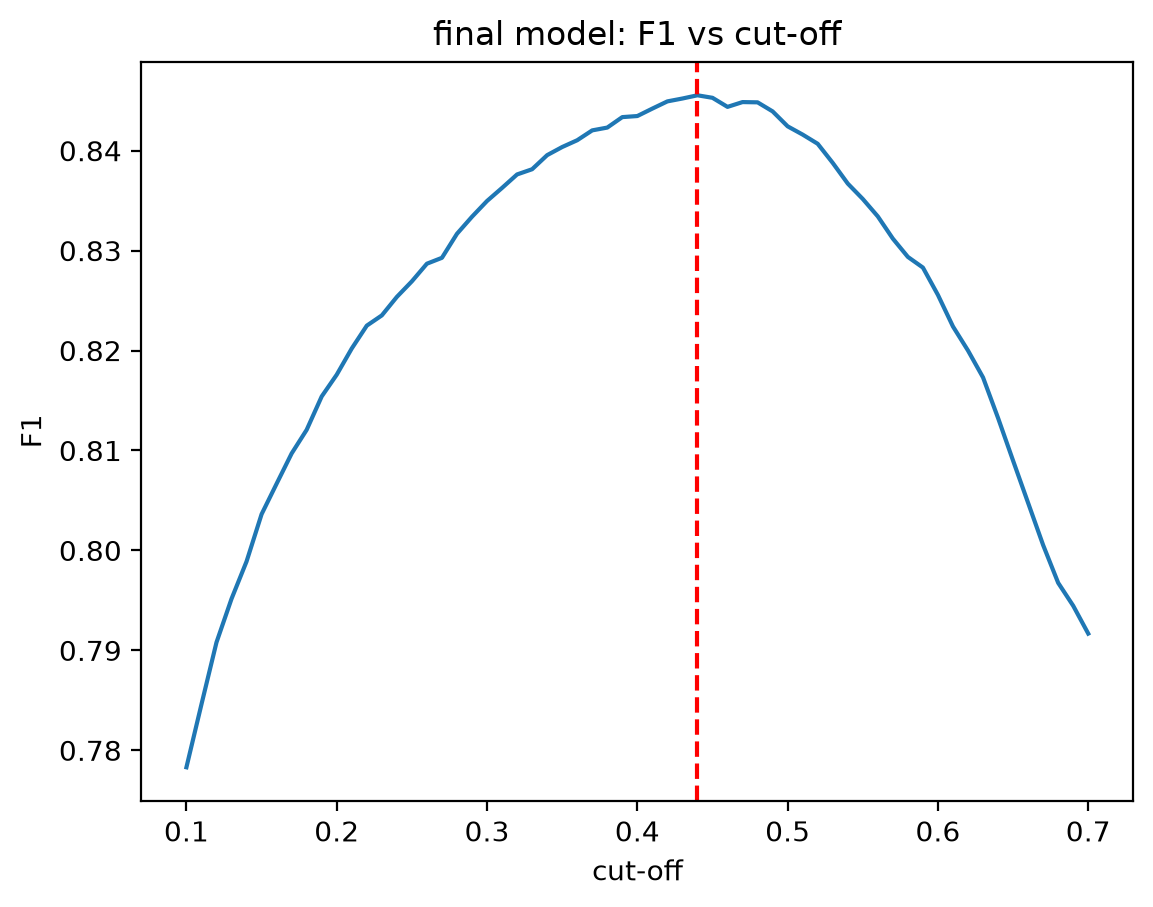

In [46]:
# F1 for every cut-off, final model (mine + Paul's 6 + recency, small trees)
import matplotlib.pyplot as plt
plt.plot(thresholds, f1s_rec)
plt.axvline(thresholds[np.argmax(f1s_rec)], color="red", linestyle="--")   # best cut-off (0.44)
plt.xlabel("cut-off")
plt.ylabel("F1")
plt.title("final model: F1 vs cut-off")
plt.show()

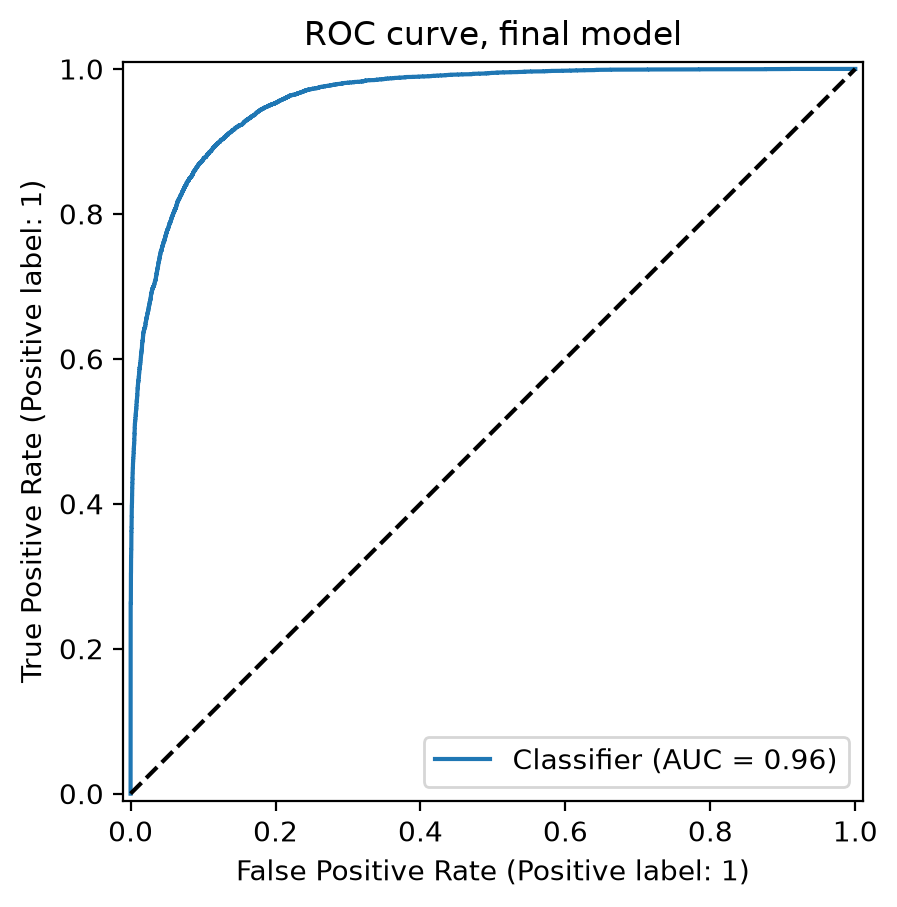

In [47]:
# roc curve of my final model (cross-validation predictions)
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(y_train, oof_rec)
plt.plot([0, 1], [0, 1], "k--")        # random guess
plt.title("ROC curve, final model")
plt.show()

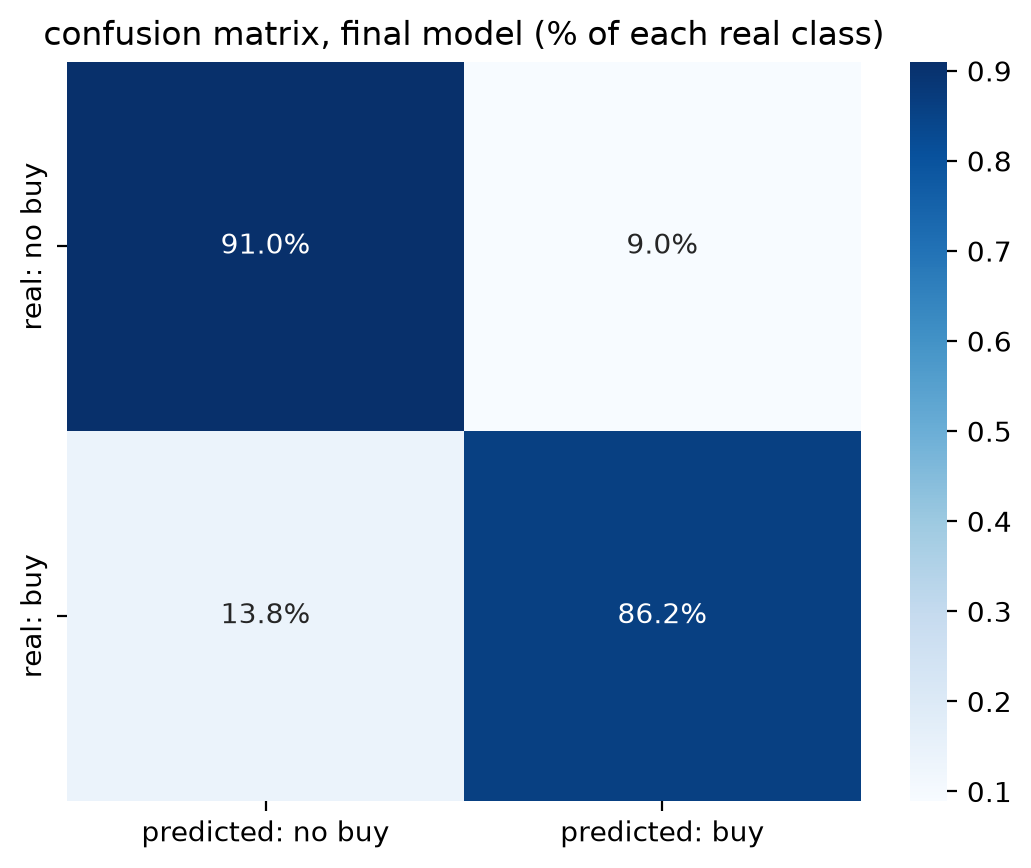

In [48]:
# confusion matrix of my final model, in % of each real class
from sklearn.metrics import confusion_matrix
import seaborn as sns

cut = thresholds[np.argmax(f1s_rec)]           # best cut-off of the final model
pred = (oof_rec >= cut).astype(int)

cm = pd.DataFrame(confusion_matrix(y_train, pred, normalize="true"),
                  index=["real: no buy", "real: buy"],
                  columns=["predicted: no buy", "predicted: buy"])
sns.heatmap(cm, annot=True, fmt=".1%", cmap="Blues")
plt.title("confusion matrix, final model (% of each real class)")
plt.show()

artist_saves                 0.268
R_recent_share               0.123
travel_date_match            0.093
app_artist_saved_rate        0.070
app_artist_play_share        0.067
R_plays_last_14d             0.065
typical_ticket_spend         0.052
price_vs_usual               0.049
travel_gap_days              0.036
artist_share                 0.030
lead_gap                     0.023
artist_days_since_last       0.017
distance_km_home_to_venue    0.017
artist_name                  0.014
travel_to_venue              0.013
price_tier                   0.010
app_plays_last_14d           0.006
app_total_plays              0.006
event_page_visits_7d         0.006
discount_pct                 0.005
dtype: float64
features never used: 2


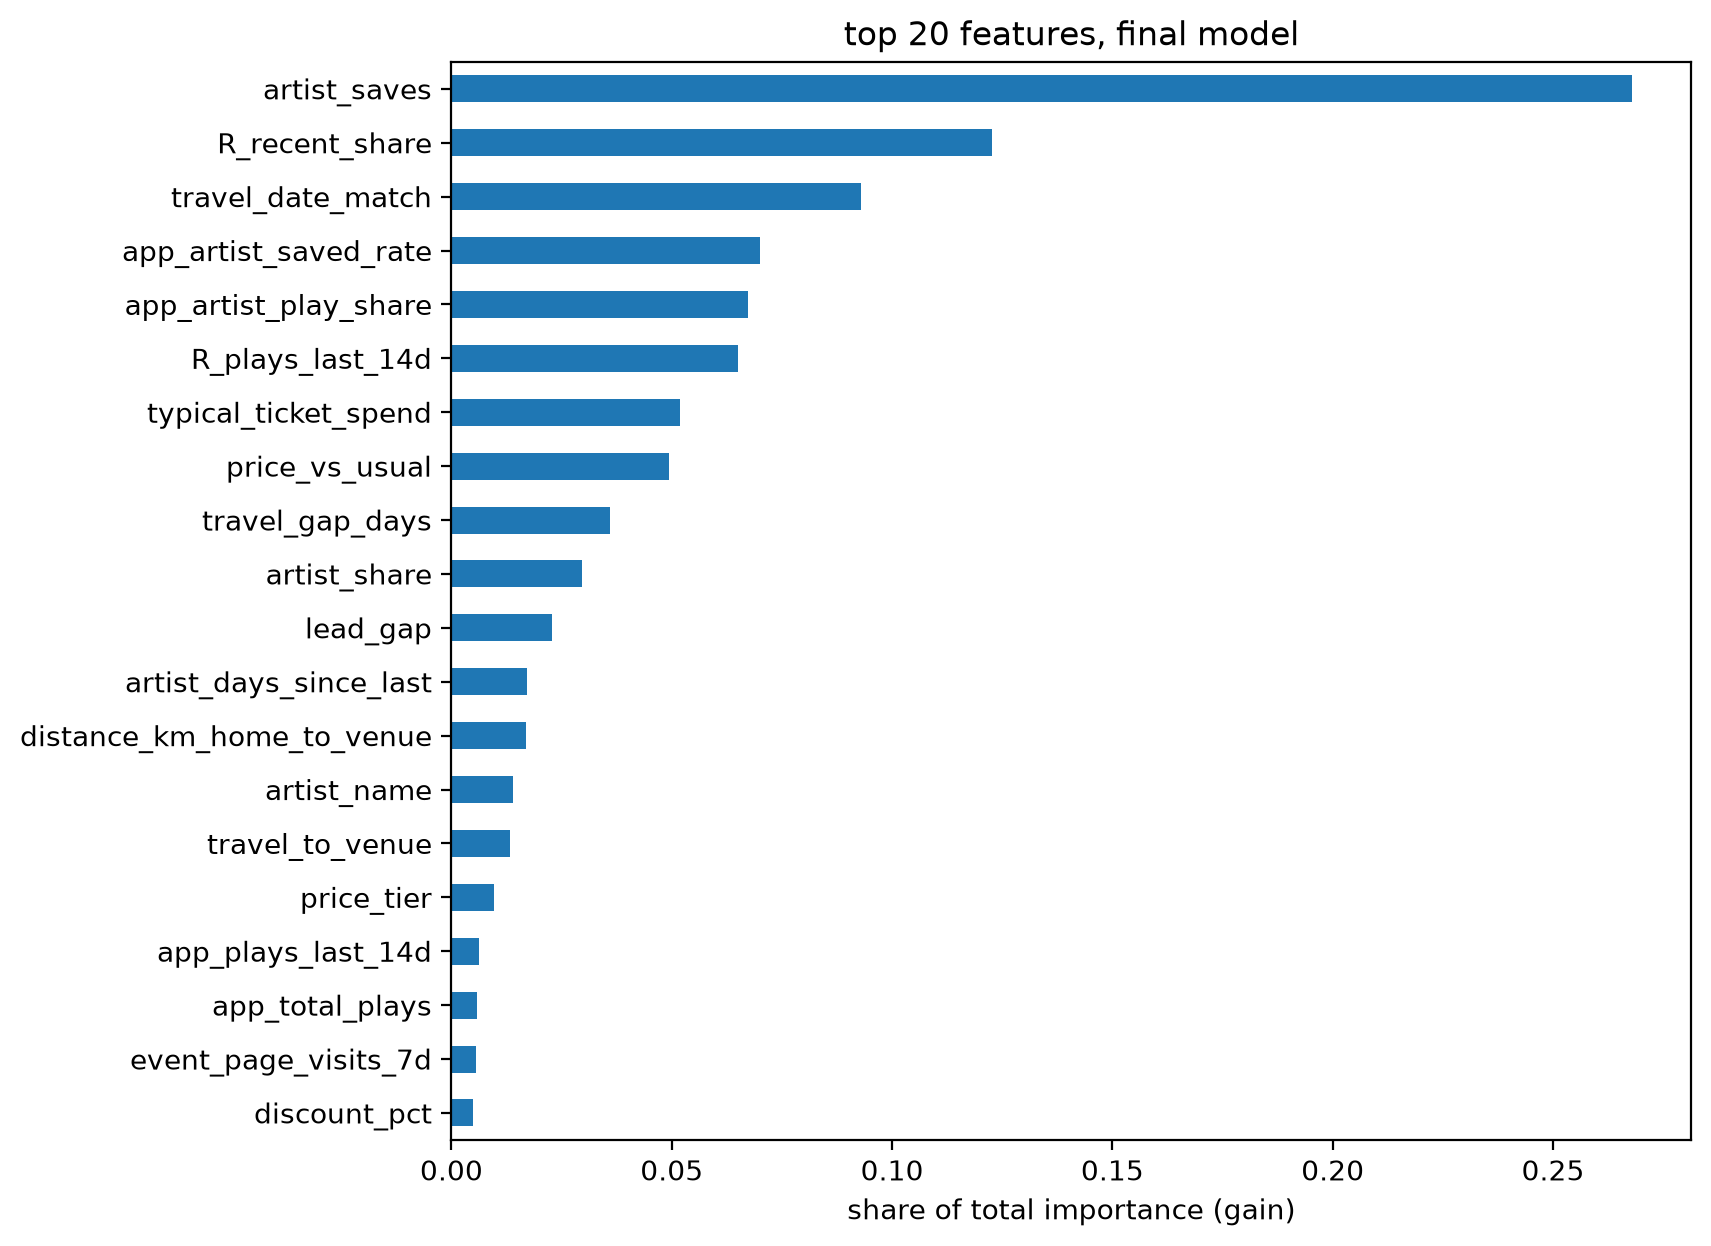

In [49]:
# which features does my final model rely on most?
importance = pd.Series(model.booster_.feature_importance("gain"), index=X_all.columns)
importance = (importance / importance.sum()).sort_values(ascending=False)   # share of total, adds up to 100%

print(importance.head(20).round(3))
print("features never used:", (importance == 0).sum())

importance.head(20).sort_values().plot(kind="barh", figsize=(8, 7))
plt.xlabel("share of total importance (gain)")
plt.title("top 20 features, final model")
plt.show()